cell annotation using scarches

In [1]:
# scarches
import scanpy as sc
import seaborn as sns
import torch
import scarches as sca
from scarches.dataset.trvae.data_handling import remove_sparsity
import matplotlib.pyplot as plt
import numpy as np
import gdown
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
sc.settings.set_figure_params(dpi=200, frameon=False)
sc.set_figure_params(dpi=200)
sc.set_figure_params(figsize=(4, 4))
torch.set_printoptions(precision=3, sci_mode=False, edgeitems=7)

 captum (see https://github.com/pytorch/captum).


In [2]:
#pip install --upgrade anndata scanpy h5py

In [3]:
# set anndata keys
condition_key = 'donor_id'
cell_type_key = 'pec_subcluster_0.80'

In [4]:
source_adata = sc.read_h5ad('/data/ep924610/kidney_biopsy/trajectory_pec/pec_annotated.h5ad'
)


In [5]:
source_adata

AnnData object with n_obs × n_vars = 4707 × 21841
    obs: 'donor_id', 'nCount_RNA', 'nFeature_RNA', 'nCount_SCT', 'nFeature_SCT', 'Sample', 'Group', 'date_of_biopsy_h5ad', 'ACEi', 'AT2i', 'Statin', 'corticosteroids_h5ad', 'region', 'RNAversion', 'nCounts_RNA', 'nFeatures_RNA', 'percMT_RNA', 'is_cell', 'QC1', 'pANN', 'DF', 'sclust_A', 'sclust_B', 'sclust_C', 'sclust_D', 'sclust_E', 'clust_A', 'clust_B', 'clust_C', 'clust_D', 'clust_E', 'predicted.annotation.l3.score', 'predicted.annotation.l3', 'predicted.annotation.l3.MappingScore', 'predicted.annotation.l1', 'predicted.annotation.l2', 'unfiltered_Doublets', 'leiden01', 'leiden03', 'leiden02', 'leiden04', 'subcluster_01_do_not_use', 'subcluster_02_do_not_use', 'subcluster_03_do_not_use', 'Main_Cluster_do_not_use', 'Cell_types_KPMP_do_not_use', 'Cell_types_Subclustering_do_not_use', 'Cell_types_Subclustering2_do_not_use', 'barcode_sample', 'main_class', 'subcluster', 'Study', 'library_id', 'percent.er', 'percent.mt', 'subclass.l2', 'su

In [6]:
source_adata.obs['pec_subcluster_0.80'].value_counts()

pec_subcluster_0.80
0_PEC/aPT1          962
7_aPEC              682
5_SPP1⁺ aPT/aPEC    599
4_PEC/aPT3          538
1_PEC/aPT2          444
9_Pod/PEC           333
3_Pod/PEC           331
6_WT1+ PEC          320
2_aPECs             255
8_aPEC/inflPEC      221
10_Pod               22
Name: count, dtype: int64

In [7]:
target_adata = sc.read_h5ad("/data/Kramann_lab/kidney_biopsy/results/xenium/leon/xenium_with_niches.h5ad")
target_adata

AnnData object with n_obs × n_vars = 198361 × 468
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'TMA_ID', 'sample', 'predic', 'leiden', 'cell_type_manual', 'condition', 'latent_leiden_0.4', 'Add-on_26_GP', 'TENM4_ligand_receptor_GP', 'Add-on_66_GP', 'Add-on_33_GP', 'Add-on_55_GP', 'Add-on_15_GP', 'Add-on_12_GP', 'Add-on_75_GP', 'NTN4_combined_GP', 'CA12_ligand_receptor_target_gene_GP', 'Add-on_39_GP', 'Add-on_38_GP', 'Add-on_8_GP', 'Add-on_24_GP', 'CCL8_combined_GP', 'Add-on_76_GP', 'MMP7_ligand_receptor_target_gene_GP', 'TGFBR3_ligand_receptor_GP', 'PTPRC_ligand_receptor_target_gene_GP', 'Add-on_22_GP', 'Add-on_18_GP', 'in_damaged', 'in_diseased_area', 'in_diseased_tubule', 'in_fibrosis', 'in_glom', 'in_healthy_area', 'in_healthy_tubule

In [8]:
target_adata.obs["cell_type_manual"] = target_adata.obs["cell_type_manual"].replace(
    {"EC/Pericyte/VSMC": "MC/Pericyte/VSMC"}
)
# (Optional) cast back to categorical and drop unused
target_adata.obs["cell_type_manual"] = target_adata.obs["cell_type_manual"].astype("category")

/tmp/ipykernel_1944884/328656011.py:1: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  target_adata.obs["cell_type_manual"] = target_adata.obs["cell_type_manual"].replace(


In [9]:
list(target_adata.obs["cell_type_manual"].unique())

['PC',
 'PT/aPT',
 'DCT',
 'distale nephron/PC/IC',
 'PT',
 'TAL/distale nephron',
 'aPT/PEC',
 'Immune',
 'MC/Pericyte/VSMC',
 'cycling/injured epithelial cells/EC',
 'dPT/dTAL/dDCT 2',
 'dPT/dTAL/dDCT 1',
 'EC',
 'B',
 'Fib/MyoFib',
 'PEC/Glom',
 'Pod/Glom',
 'PL/B',
 'Cyc mesenchymal',
 'Mesenchymal',
 'Progenitor-like epithelial cells']

In [10]:
import numpy as np

keep = np.isin(target_adata.obs["cell_type_manual"], ["PEC/Glom"])
target_adata = target_adata[keep].copy()

In [11]:
target_adata.obs["cell_type_manual"] = target_adata.obs["cell_type_manual"].astype("category")
target_adata.obs["cell_type_manual"].cat.remove_unused_categories()

XETG00229__0041734__Region_3__20250416__104148-2152     PEC/Glom
XETG00229__0041734__Region_3__20250416__104148-2758     PEC/Glom
XETG00229__0041734__Region_3__20250416__104148-2983     PEC/Glom
XETG00229__0041734__Region_3__20250416__104148-4020     PEC/Glom
XETG00229__0041734__Region_3__20250416__104148-4330     PEC/Glom
                                                          ...   
XETG00229__0042348__Region_3__20250416__104148-62038    PEC/Glom
XETG00229__0042348__Region_3__20250416__104148-62702    PEC/Glom
XETG00229__0042348__Region_3__20250416__104148-62858    PEC/Glom
XETG00229__0042348__Region_3__20250416__104148-63096    PEC/Glom
XETG00229__0042348__Region_3__20250416__104148-63670    PEC/Glom
Name: cell_type_manual, Length: 2187, dtype: category
Categories (1, object): ['PEC/Glom']

In [12]:
humanized_adata = target_adata

In [13]:
source_adata = source_adata.copy()
common_genes = np.intersect1d(humanized_adata.var_names, source_adata.var_names)
source_adata =source_adata[:, common_genes].copy()

# 16200 common genes

In [14]:
source_adata

AnnData object with n_obs × n_vars = 4707 × 468
    obs: 'donor_id', 'nCount_RNA', 'nFeature_RNA', 'nCount_SCT', 'nFeature_SCT', 'Sample', 'Group', 'date_of_biopsy_h5ad', 'ACEi', 'AT2i', 'Statin', 'corticosteroids_h5ad', 'region', 'RNAversion', 'nCounts_RNA', 'nFeatures_RNA', 'percMT_RNA', 'is_cell', 'QC1', 'pANN', 'DF', 'sclust_A', 'sclust_B', 'sclust_C', 'sclust_D', 'sclust_E', 'clust_A', 'clust_B', 'clust_C', 'clust_D', 'clust_E', 'predicted.annotation.l3.score', 'predicted.annotation.l3', 'predicted.annotation.l3.MappingScore', 'predicted.annotation.l1', 'predicted.annotation.l2', 'unfiltered_Doublets', 'leiden01', 'leiden03', 'leiden02', 'leiden04', 'subcluster_01_do_not_use', 'subcluster_02_do_not_use', 'subcluster_03_do_not_use', 'Main_Cluster_do_not_use', 'Cell_types_KPMP_do_not_use', 'Cell_types_Subclustering_do_not_use', 'Cell_types_Subclustering2_do_not_use', 'barcode_sample', 'main_class', 'subcluster', 'Study', 'library_id', 'percent.er', 'percent.mt', 'subclass.l2', 'subc

In [15]:
source_adata.X

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 465846 stored elements and shape (4707, 468)>

In [16]:
#creating model for reference dataset
# Normalizing to median total counts
#sc.pp.normalize_total(source_adata)
# Logarithmize the data
#sc.pp.log1p(source_adata)
#sc.pp.highly_variable_genes(
#    source_adata, n_top_genes=2000, batch_key="donor_id", subset=True
#)
sca.models.SCVI.setup_anndata(source_adata, batch_key=condition_key, labels_key=cell_type_key)
vae = sca.models.SCVI(
    source_adata,
    n_layers=2,
    encode_covariates=True,
    deeply_inject_covariates=False,
    use_layer_norm="both",
    use_batch_norm="none",
)
vae.train(max_epochs = 100)
scanvae = sca.models.SCANVI.from_scvi_model(vae, unlabeled_category = "Unknown")
scanvae.train(max_epochs=100)
# create anndata file of latent representation
reference_latent = sc.AnnData(scanvae.get_latent_representation())
reference_latent.obs["cell_type"] = source_adata.obs[cell_type_key].tolist()
reference_latent.obs["batch"] = source_adata.obs[condition_key].tolist()
sc.pp.neighbors(reference_latent, n_neighbors=8)
sc.tl.leiden(reference_latent)
sc.tl.umap(reference_latent) 


/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/scvi/data/fields/_dataframe_field.py:187: UserWarning: Category 9 in adata.obs['_scvi_batch'] has fewer than 3 cells. Models may not train properly.
  categorical_mapping = _make_column_categorical(
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /data/ep924610/miniforge3/envs/scarches/lib/python3. ...
INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_

Training:   0%|          | 0/100 [00:00<?, ?it/s]

/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  w

/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  w

/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  w

/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  w

... (5 outputs left out)

/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  w

/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  w

/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  w

/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  w

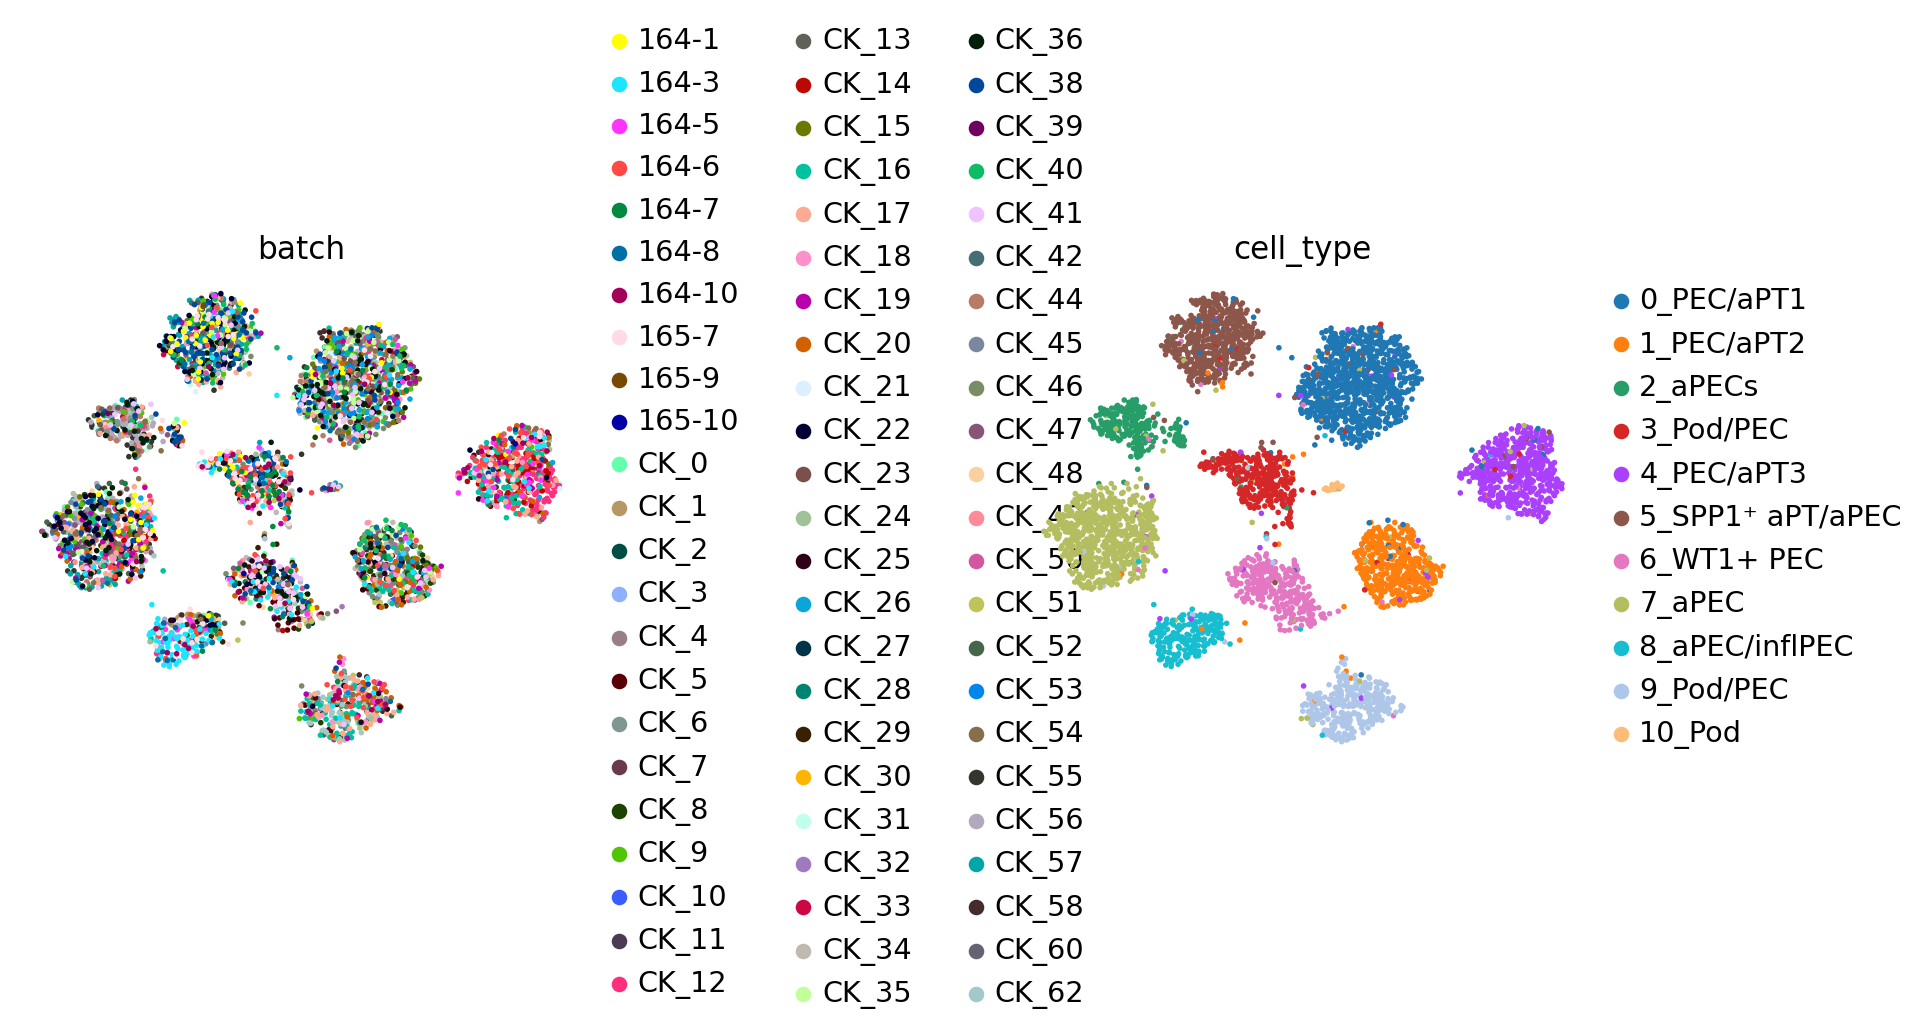

In [17]:
sc.pl.umap(reference_latent,
           color=['batch', 'cell_type'],
           frameon=False,
           wspace=0.6
           )

In [18]:
humanized_adata.var_names_make_unique() 
humanized_adata = humanized_adata[:, source_adata.var_names].copy()
humanized_adata

AnnData object with n_obs × n_vars = 2187 × 468
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'TMA_ID', 'sample', 'predic', 'leiden', 'cell_type_manual', 'condition', 'latent_leiden_0.4', 'Add-on_26_GP', 'TENM4_ligand_receptor_GP', 'Add-on_66_GP', 'Add-on_33_GP', 'Add-on_55_GP', 'Add-on_15_GP', 'Add-on_12_GP', 'Add-on_75_GP', 'NTN4_combined_GP', 'CA12_ligand_receptor_target_gene_GP', 'Add-on_39_GP', 'Add-on_38_GP', 'Add-on_8_GP', 'Add-on_24_GP', 'CCL8_combined_GP', 'Add-on_76_GP', 'MMP7_ligand_receptor_target_gene_GP', 'TGFBR3_ligand_receptor_GP', 'PTPRC_ligand_receptor_target_gene_GP', 'Add-on_22_GP', 'Add-on_18_GP', 'in_damaged', 'in_diseased_area', 'in_diseased_tubule', 'in_fibrosis', 'in_glom', 'in_healthy_area', 'in_healthy_tubule',

Acc: 0.9509241555130656
INFO     File ./ref/model.pt already downloaded                                                                    
Labelled Indices:  0
Unlabelled Indices:  2187
INFO     Training for 50 epochs.                                                                                   


/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /data/ep924610/miniforge3/envs/scarches/lib/python3. ...
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/scvi/data/fields/_dataframe_field.py:227: UserWarning: Category 83 in adata.obs['_scvi_batch'] has fewer than 3 cells. Models may not train properly.
  new_mapping = _make_column_categorical(
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarc

Training:   0%|          | 0/50 [00:00<?, ?it/s]

/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  w

/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  w

/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/data/ep924610/miniforge3/envs/scarches/lib/python3.10/site-packages/torch/cuda/__init__.py:829: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
INFO: `Trainer.fit` stopped: `max_epochs=50` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=50` reached.


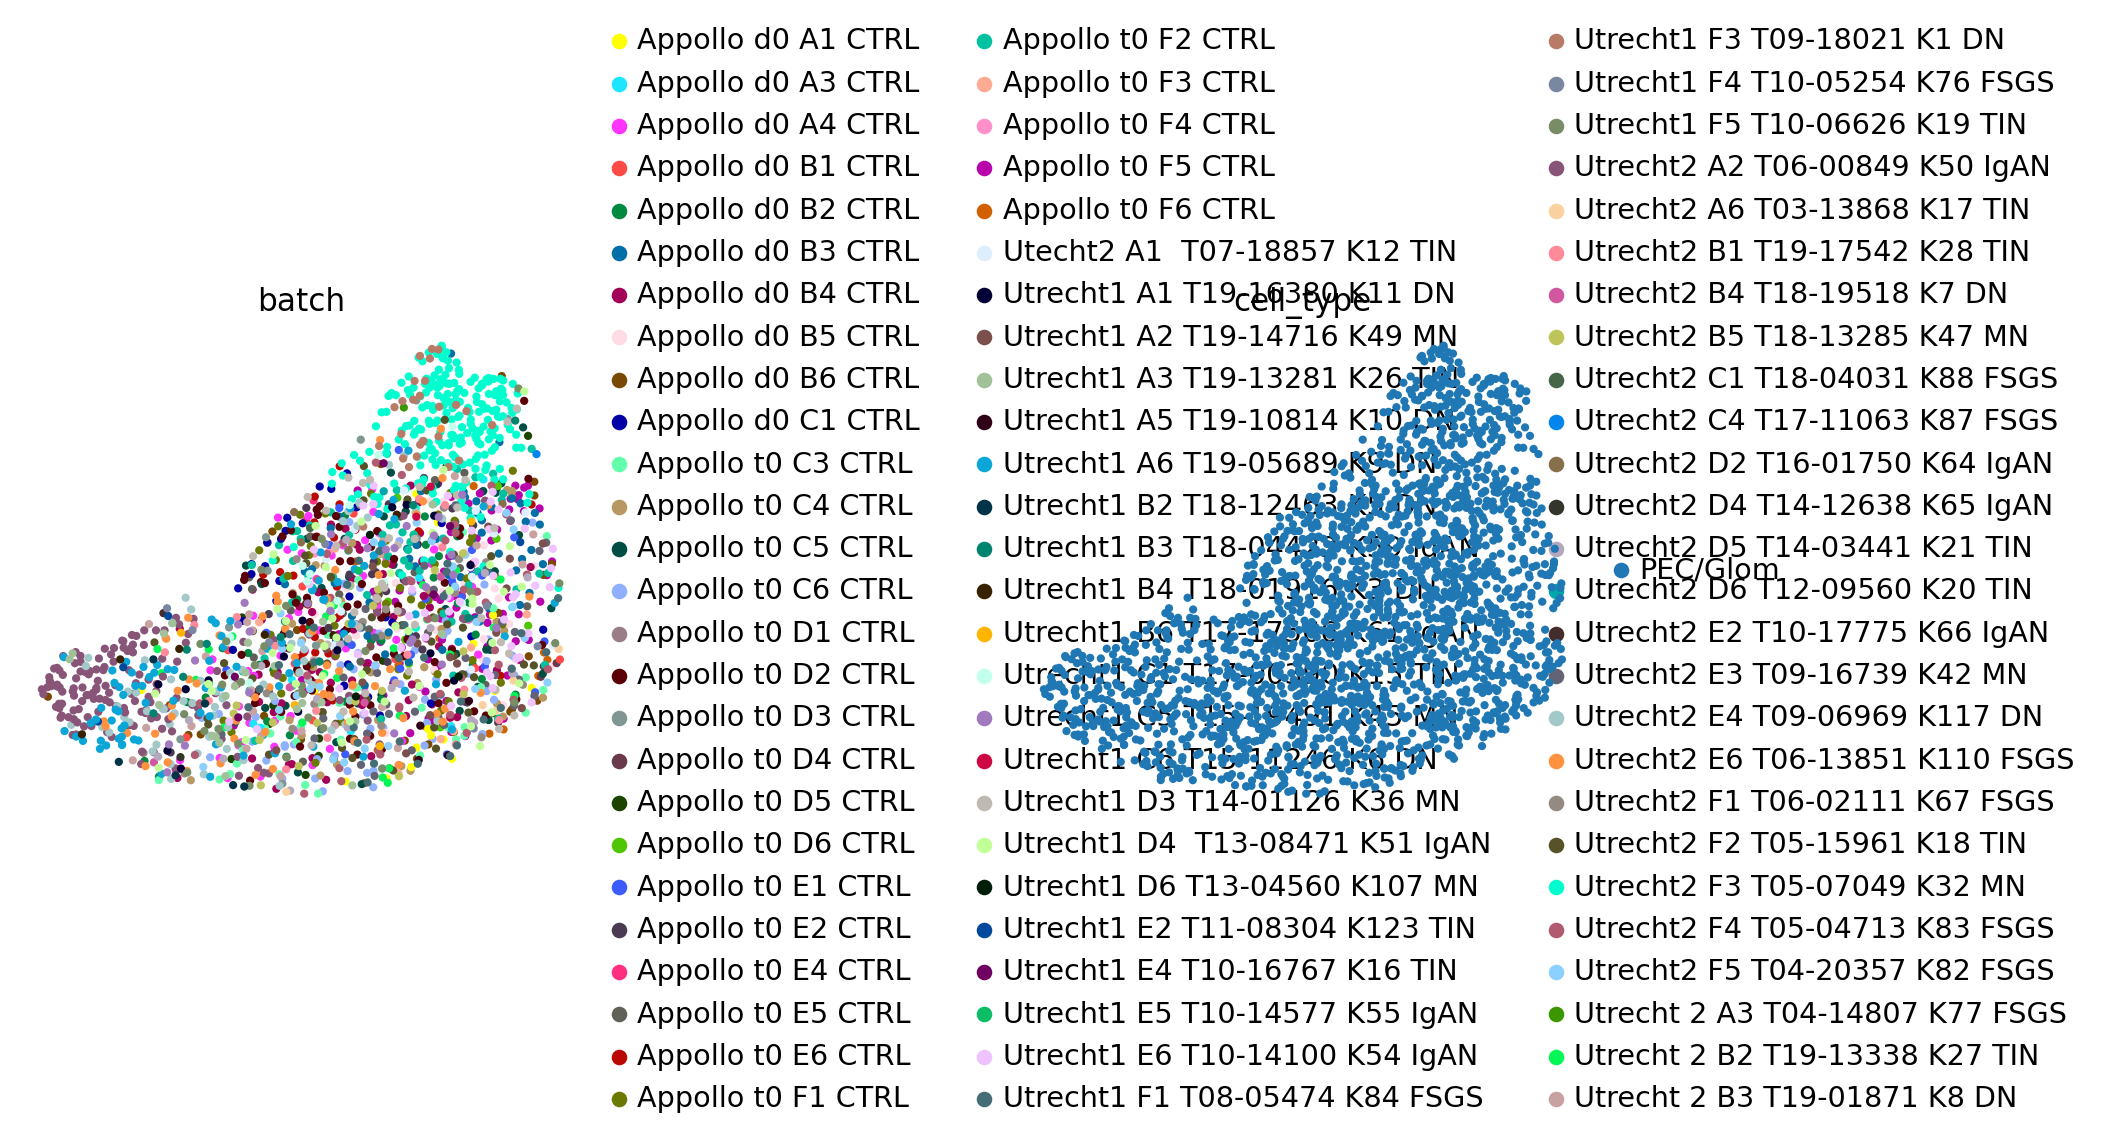

In [19]:
#creating target data
sc.pp.neighbors(humanized_adata)
sc.tl.leiden(humanized_adata, flavor="igraph", n_iterations=2)

humanized_adata.obs.rename(columns={"TMA_ID": condition_key}, inplace=True)
humanized_adata.obs.rename(columns={"cell_type_manual": cell_type_key}, inplace=True)
reference_latent.obs['predictions'] = scanvae.predict()
print("Acc: {}".format(np.mean(reference_latent.obs.predictions == reference_latent.obs.cell_type)))

# save models 
ref_path = './ref'
scanvae.save(ref_path, overwrite=True)

humanized_adata.obs['orig_cell_types'] = humanized_adata.obs[cell_type_key].copy() 
humanized_adata.obs[cell_type_key] = scanvae.unlabeled_category_
# model 
model = sca.models.SCANVI.load_query_data(
    humanized_adata,
    ref_path,
    freeze_dropout = True,
)
model._unlabeled_indices = np.arange(humanized_adata.n_obs)
model._labeled_indices = []
print("Labelled Indices: ", len(model._labeled_indices))
print("Unlabelled Indices: ", len(model._unlabeled_indices))

model.train(
    max_epochs=50,
    plan_kwargs=dict(weight_decay=0.0),
    check_val_every_n_epoch=10,
)

query_latent = sc.AnnData(model.get_latent_representation())
query_latent.obs['cell_type'] = humanized_adata.obs['orig_cell_types'].tolist()
query_latent.obs['batch'] = humanized_adata.obs[condition_key].tolist()

sc.pp.neighbors(query_latent)
sc.tl.leiden(query_latent)
sc.tl.umap(query_latent)
sc.pl.umap(
    query_latent,
    color=["batch", "cell_type"],
    frameon=False,
    wspace=0.6, save = 'mapping_umap.pdf'
)


/tmp/ipykernel_1944884/2082416681.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = query_latent.obs.groupby(["cell_type", "predictions"]).size().unstack(fill_value=0)


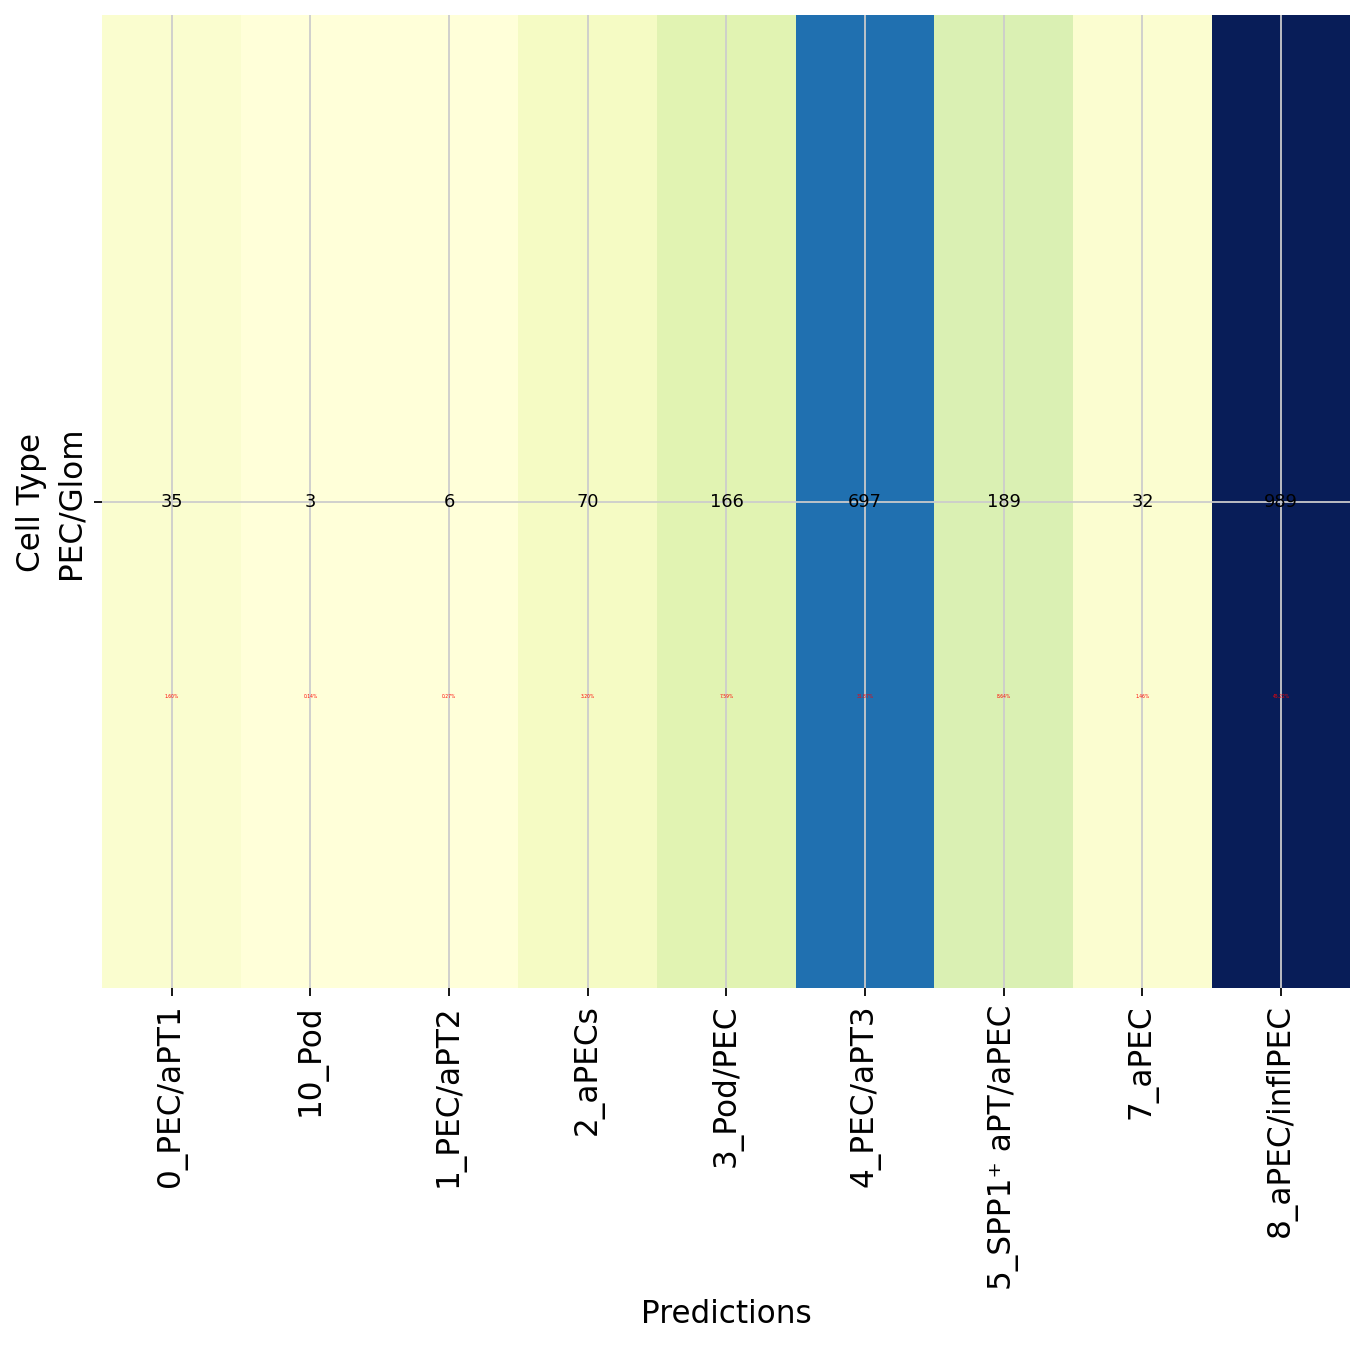

In [20]:
surgery_path = './modelres'
model.save(surgery_path, overwrite=True)

query_latent.obs['predictions'] = model.predict()

df = query_latent.obs.groupby(["cell_type", "predictions"]).size().unstack(fill_value=0)
norm_df = df / df.sum(axis=0)

# Calculate row-wise percentages
row_sums = df.sum(axis=1)
percentage_df = df.divide(row_sums, axis=0) * 100

# Plot the heatmap without borders and grid lines
plt.figure(figsize=(10, 8))
heatmap = sns.heatmap(df, annot=False, cmap='YlGnBu', cbar=False, linewidths=0.5, linecolor='none')

# Set the style of the heatmap cells to remove edges
for _, spine in heatmap.spines.items():
    spine.set_visible(False)

# Add custom annotations for count values
for i in range(df.shape[0]):
    for j in range(df.shape[1]):
        raw_value = df.iloc[i, j]
        plt.text(j + 0.5, i + 0.5, f"{raw_value}", ha='center', va='center', fontsize=8)

# Add custom annotations for percentage values
for i in range(percentage_df.shape[0]):
    for j in range(percentage_df.shape[1]):
        percentage_value = percentage_df.iloc[i, j]
        plt.text(j + 0.5, i + 0.7, f"{percentage_value:.2f}%", ha='center', va='center', fontsize=2, color='red')

# Set axis labels and rotate x-axis labels by 90 degrees
plt.xlabel("Predictions")
plt.ylabel("Cell Type")
plt.xticks(rotation=90)
plt.savefig('heatmap_prediction_resolution_.pdf')
# Show plot
plt.show()

df.to_csv('./prediction_pec/resolution_prediction_df.csv')
norm_df.to_csv('./prediction_pec/resolution_prediction_normalised_df.csv')
pd.DataFrame(common_genes).to_csv('./prediction_pec/resolution_common_genes.csv')
pd.DataFrame(source_adata.var_names.tolist()).to_csv('./prediction_pec/resolution__highly_variable_source.csv')
query_latent.write_h5ad('./prediction_pec/file_after_predictions.h5ad')
query_latent.obs.to_csv('./prediction_pec/predictions_incsv.csv')

In [21]:
query_latent.obs

,cell_type,batch,leiden,predictions
0,PEC/Glom,Appollo t0 C3 CTRL,1,3_Pod/PEC
1,PEC/Glom,Appollo d0 B2 CTRL,2,5_SPP1⁺ aPT/aPEC
2,PEC/Glom,Appollo t0 C4 CTRL,11,4_PEC/aPT3
3,PEC/Glom,Appollo t0 D2 CTRL,2,8_aPEC/inflPEC
4,PEC/Glom,Appollo t0 F5 CTRL,11,4_PEC/aPT3
...,...,...,...,...
2182,PEC/Glom,Utrecht1 C5 T15-19491 K45 MN,2,4_PEC/aPT3
2183,PEC/Glom,Utrecht1 A1 T19-16380 K11 DN,9,4_PEC/aPT3
2184,PEC/Glom,Utrecht1 E6 T10-14100 K54 IgAN,7,4_PEC/aPT3
2185,PEC/Glom,Utrecht1 E2 T11-08304 K123 TIN,7,4_PEC/aPT3


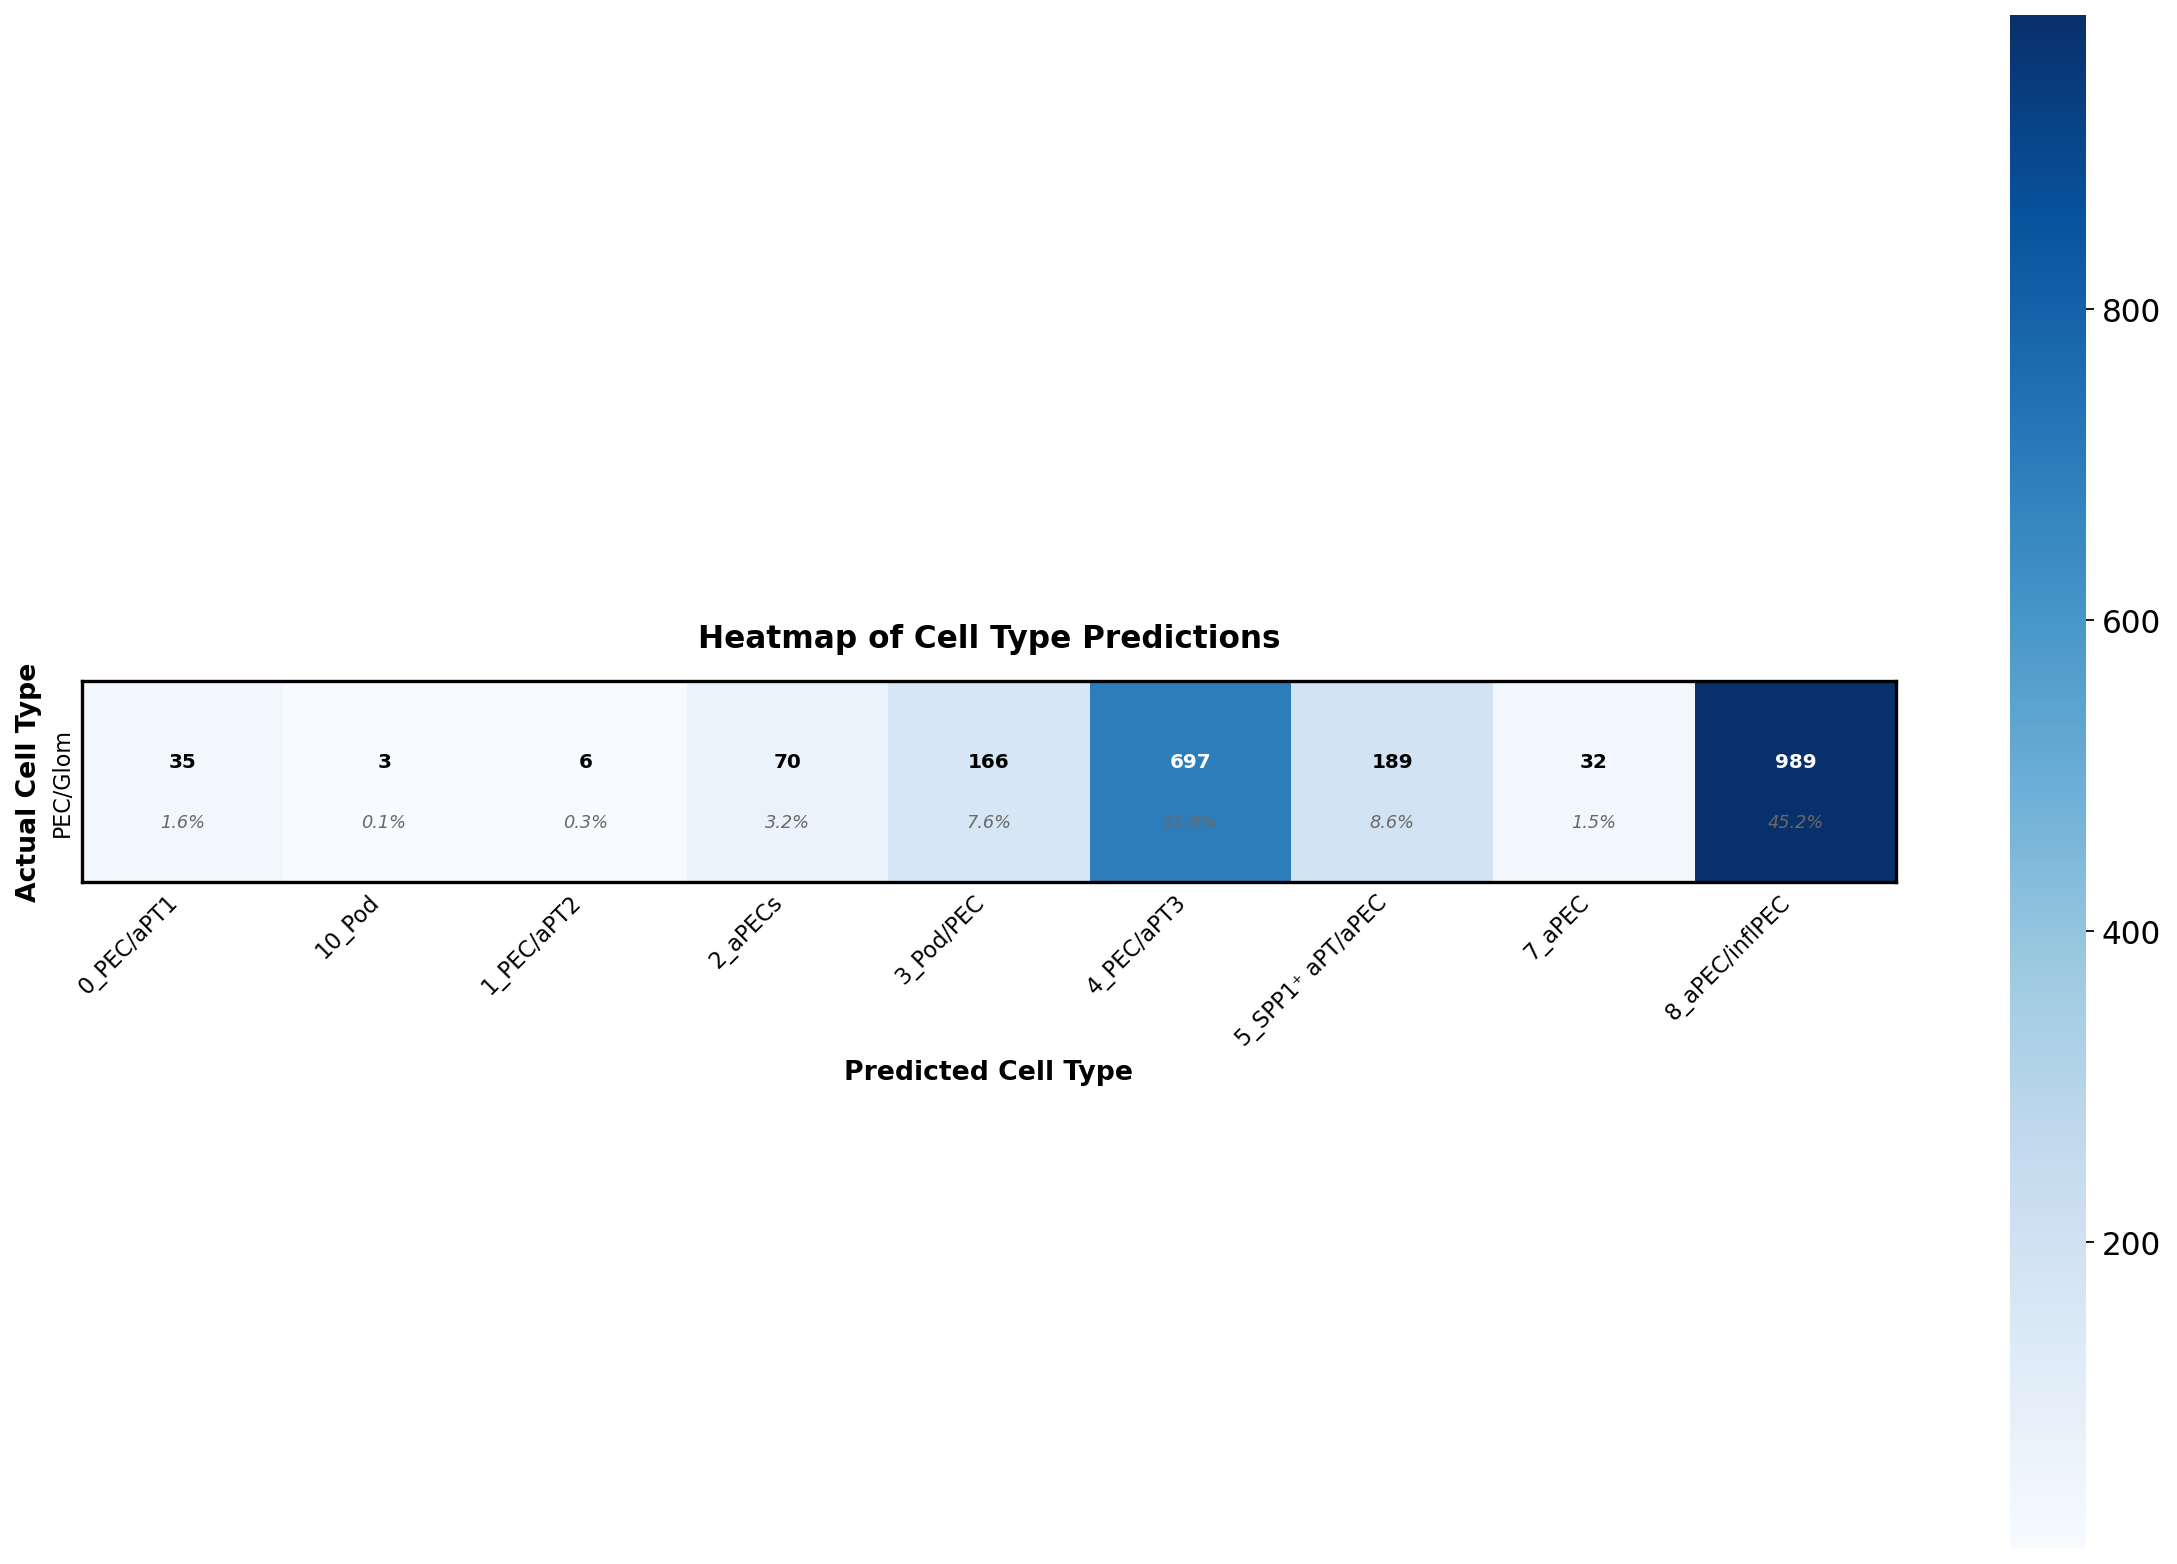

In [22]:
#creating target data

# Load Data
df = pd.read_csv('./prediction_pec/resolution_prediction_df.csv', index_col = 0)

# Normalize column-wise for proportions
norm_df = df / df.sum(axis=0)

# Calculate row-wise percentages
row_sums = df.sum(axis=1)
percentage_df = df.divide(row_sums, axis=0) * 100

# Create Figure
fig, ax = plt.subplots(figsize=(15, 10))

# Use a proper pastel colormap
pastel_cmap = sns.color_palette("Blues", as_cmap=True)

# Create heatmap with pastel colors and no internal grid lines
heatmap = sns.heatmap(
    df,
    annot=False,
    cmap=pastel_cmap,
    cbar=True,
    linewidths=0,  # Remove internal grid lines
    square=True,   # Ensure cells are square-shaped
    ax=ax
)

# Turn off the grid that might be reactivated
ax.grid(False)

# Loop through each cell to annotate with both raw and percentage values
for i in range(df.shape[0]):
    for j in range(df.shape[1]):
        raw_value = df.iloc[i, j]
        percentage_value = percentage_df.iloc[i, j]
        
        # Choose text color based on background intensity
        text_color = "black" if raw_value < df.to_numpy().max() * 0.6 else "white"
        
        # Display raw values in bold
        plt.text(j + 0.5, i + 0.4, f"{raw_value}",
                 ha='center', va='center', fontsize=9,
                 fontweight="bold", color=text_color)
        
        # Display percentages in italic dark gray
        plt.text(j + 0.5, i + 0.7, f"{percentage_value:.1f}%",
                 ha='center', va='center', fontsize=8,
                 fontstyle="italic", color="dimgray")

# Fix to ensure axis labels are shown (without bringing back grid lines)
ax.set_xlabel("Predicted Cell Type", fontsize=12, fontweight='bold')
ax.set_ylabel("Actual Cell Type", fontsize=12, fontweight='bold')

# Instead of using grid lines, we can draw a border around the entire heatmap
for _, spine in ax.spines.items():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(1.5)

ax.tick_params(axis='both', which='both', length=0)

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)

# Title
plt.title("Heatmap of Cell Type Predictions", fontsize=14, fontweight="bold", pad=15)
plt.tight_layout() 
plt.savefig('heatmap_prediction_resolution.pdf')

# Show Plot
plt.show()

In [16]:
query_latent.obs.to_csv('predictions.csv')

In [35]:
query_latent = sc.read_h5ad('./prediction_pec/file_after_predictions.h5ad')

In [36]:
target_adata = sc.read_h5ad("/data/Kramann_lab/kidney_biopsy/results/xenium/leon/xenium_with_niches.h5ad")

In [23]:
target_adata.obs["cell_type_manual"] = target_adata.obs["cell_type_manual"].replace(
    {"EC/Pericyte/VSMC": "MC/Pericyte/VSMC"}
)
# (Optional) cast back to categorical and drop unused
target_adata.obs["cell_type_manual"] = target_adata.obs["cell_type_manual"].astype("category")
import numpy as np

"""keep = np.isin(target_adata.obs["cell_type_manual"], ["PEC/Glom"])
target_adata = target_adata[keep].copy()"""
target_adata.obs["cell_type_manual"] = target_adata.obs["cell_type_manual"].astype("category")
target_adata.obs["cell_type_manual"].cat.remove_unused_categories()

XETG00229__0041734__Region_3__20250416__104148-2152     PEC/Glom
XETG00229__0041734__Region_3__20250416__104148-2758     PEC/Glom
XETG00229__0041734__Region_3__20250416__104148-2983     PEC/Glom
XETG00229__0041734__Region_3__20250416__104148-4020     PEC/Glom
XETG00229__0041734__Region_3__20250416__104148-4330     PEC/Glom
                                                          ...   
XETG00229__0042348__Region_3__20250416__104148-62038    PEC/Glom
XETG00229__0042348__Region_3__20250416__104148-62702    PEC/Glom
XETG00229__0042348__Region_3__20250416__104148-62858    PEC/Glom
XETG00229__0042348__Region_3__20250416__104148-63096    PEC/Glom
XETG00229__0042348__Region_3__20250416__104148-63670    PEC/Glom
Name: cell_type_manual, Length: 2187, dtype: category
Categories (1, object): ['PEC/Glom']

In [24]:
query_latent

AnnData object with n_obs × n_vars = 2187 × 10
    obs: 'cell_type', 'batch', 'leiden', 'predictions'
    uns: 'neighbors', 'leiden', 'umap', 'batch_colors', 'cell_type_colors'
    obsm: 'X_umap'
    obsp: 'distances', 'connectivities'

In [25]:
target_adata

AnnData object with n_obs × n_vars = 2187 × 468
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'TMA_ID', 'sample', 'predic', 'leiden', 'cell_type_manual', 'condition', 'latent_leiden_0.4', 'Add-on_26_GP', 'TENM4_ligand_receptor_GP', 'Add-on_66_GP', 'Add-on_33_GP', 'Add-on_55_GP', 'Add-on_15_GP', 'Add-on_12_GP', 'Add-on_75_GP', 'NTN4_combined_GP', 'CA12_ligand_receptor_target_gene_GP', 'Add-on_39_GP', 'Add-on_38_GP', 'Add-on_8_GP', 'Add-on_24_GP', 'CCL8_combined_GP', 'Add-on_76_GP', 'MMP7_ligand_receptor_target_gene_GP', 'TGFBR3_ligand_receptor_GP', 'PTPRC_ligand_receptor_target_gene_GP', 'Add-on_22_GP', 'Add-on_18_GP', 'in_damaged', 'in_diseased_area', 'in_diseased_tubule', 'in_fibrosis', 'in_glom', 'in_healthy_area', 'in_healthy_tubule',

In [26]:
# 1) Basic sanity check
if query_latent.n_obs != target_adata.n_obs:
    raise ValueError(f"Different n_obs: query_latent={query_latent.n_obs}, target_adata={target_adata.n_obs}")

# 2) Ensure the predictions column exists
col = "predictions"
if col not in query_latent.obs.columns:
    raise KeyError(f"Column '{col}' not found in query_latent.obs. Available: {list(query_latent.obs.columns)}")

# 3) Assign by position (ignoring index)
# Using .to_numpy() / .values guarantees positional alignment
target_adata.obs[col] = query_latent.obs[col].to_numpy()

# Optional: rename to make provenance clear
# target_adata.obs["predictions_scArches"] = query_latent.obs[col].to_numpy()

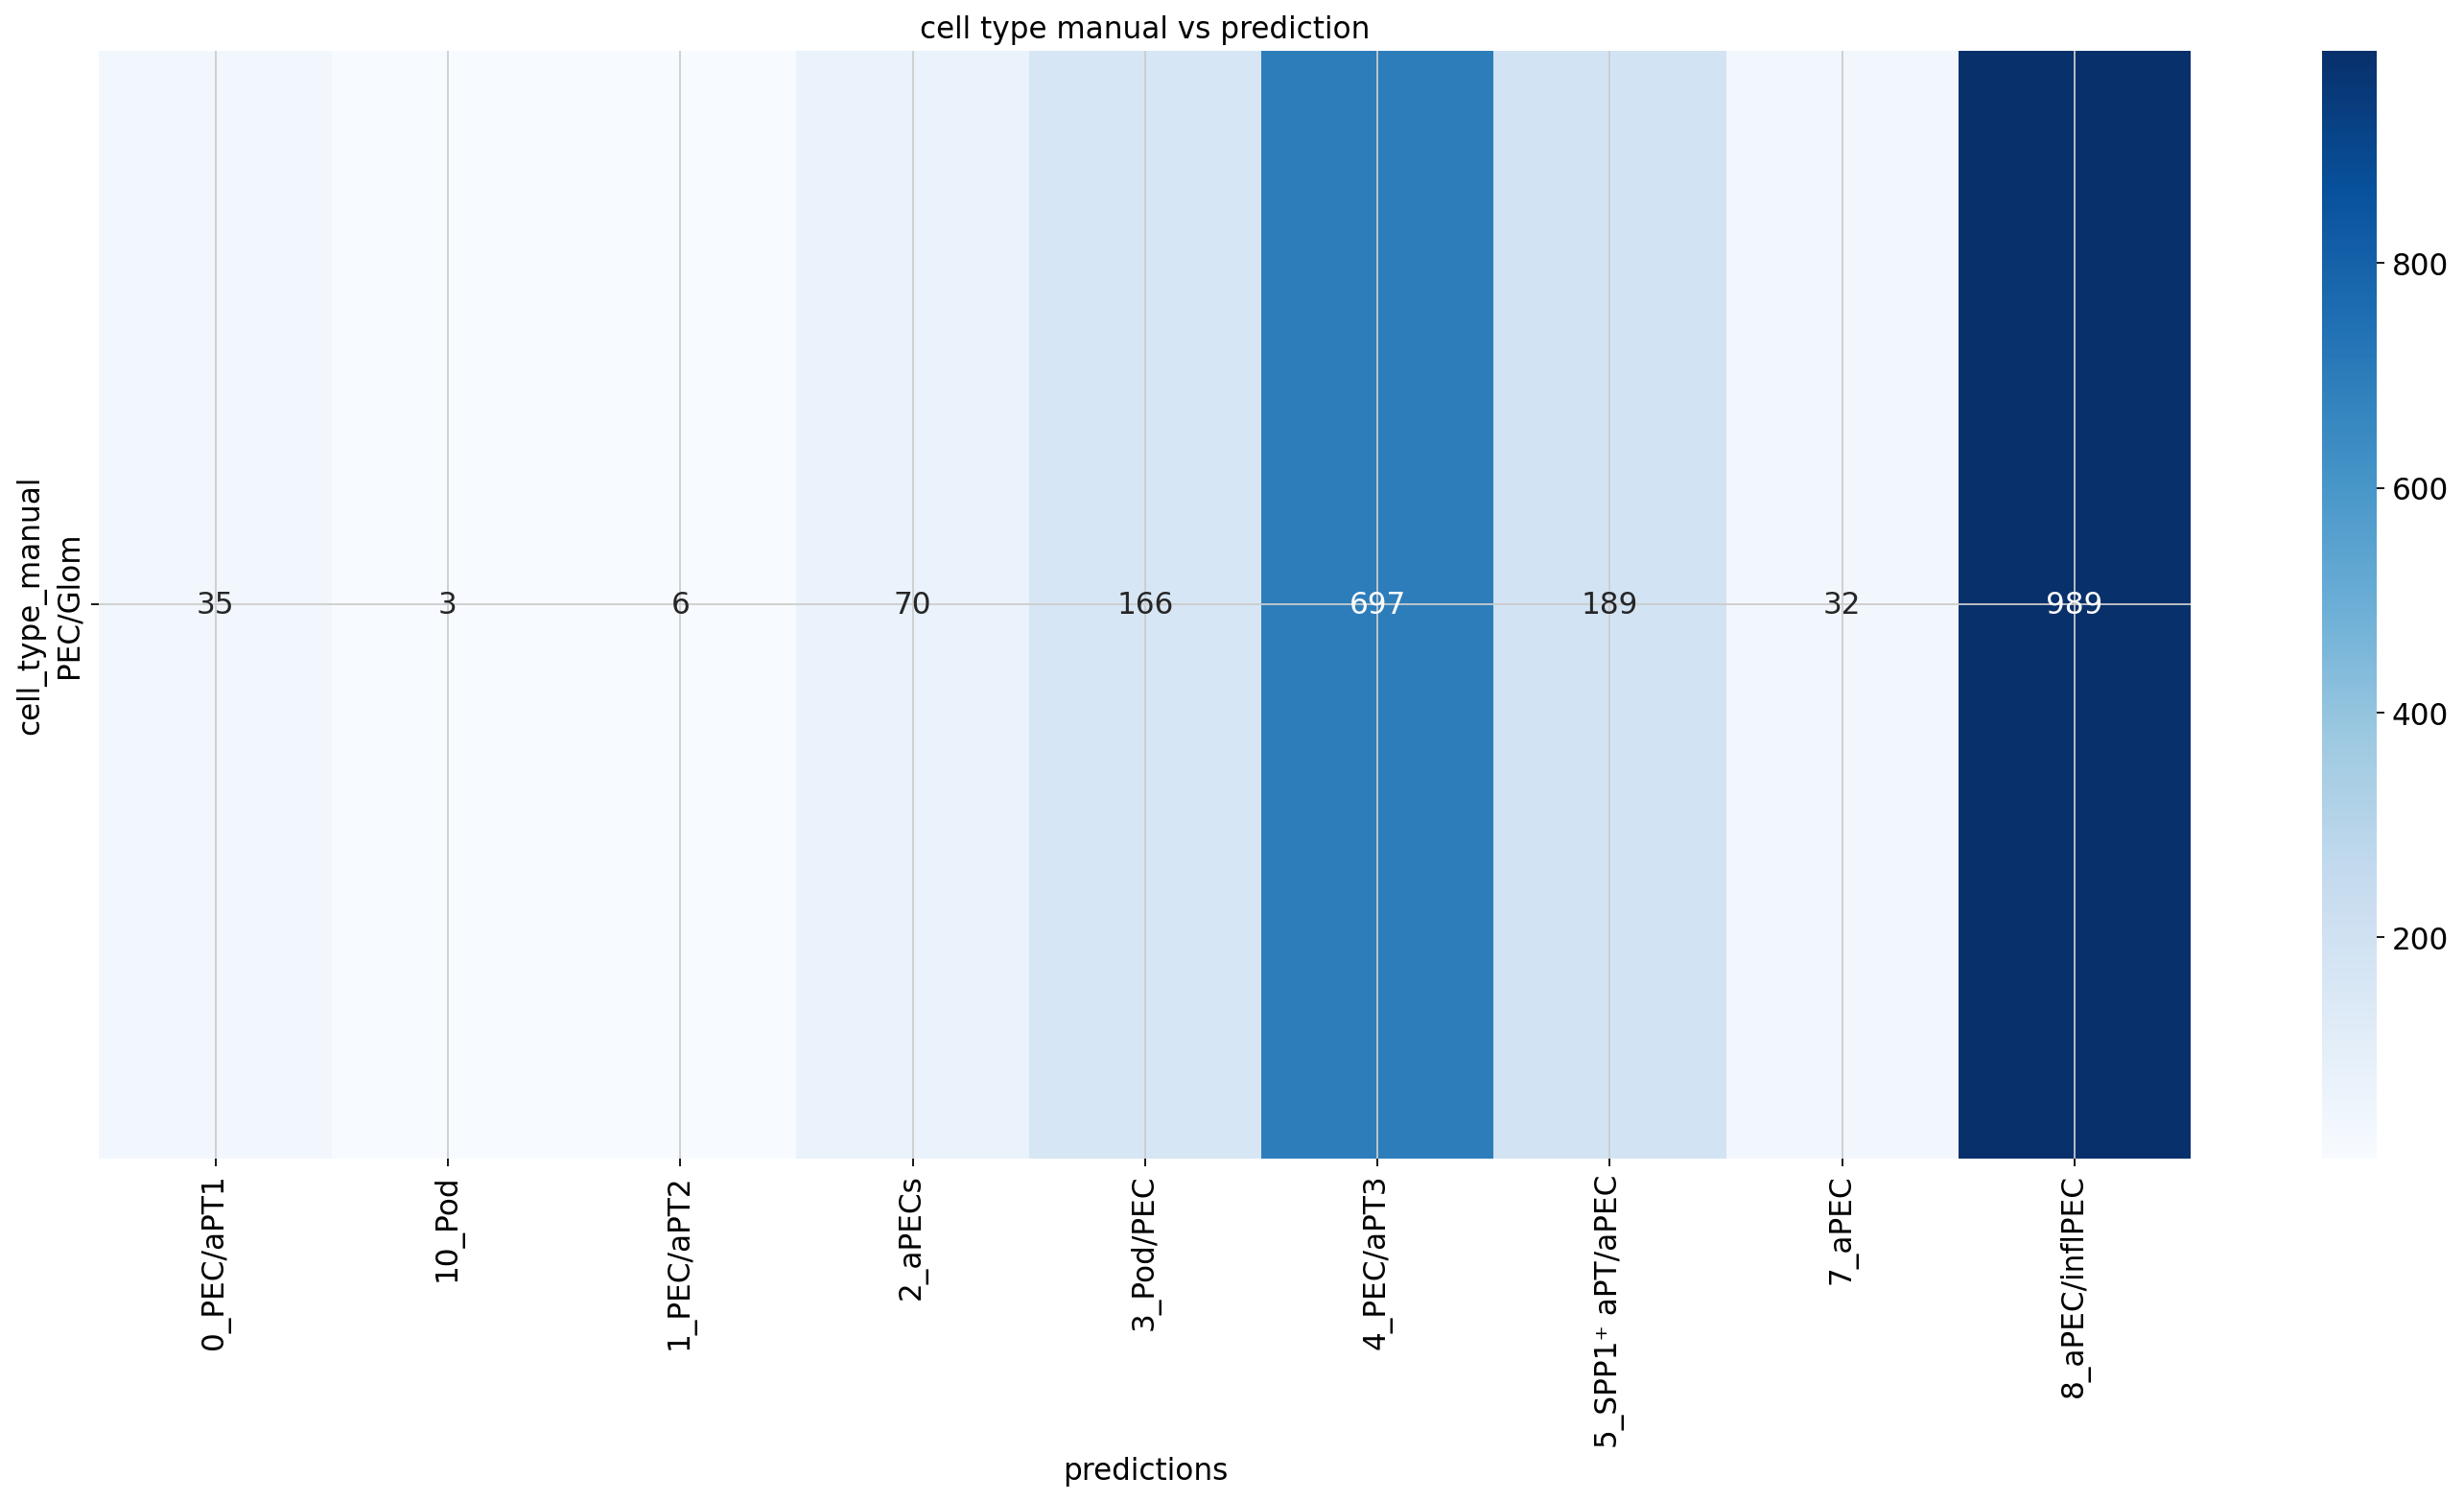

In [27]:
heatmap_data = pd.crosstab(target_adata.obs['cell_type_manual'], target_adata.obs['predictions'])
import seaborn as sns
plt.figure(figsize=(18, 10))
sns.heatmap(heatmap_data, annot=True, fmt="d", cmap="Blues")
plt.title("cell type manual vs prediction")
plt.tight_layout()
plt.savefig('heatmap_pred_vs_manual_annotation.pdf')
plt.show()

In [28]:
target_adata.write_h5ad("/data/ep924610/kidney_biopsy/prediction_pec/xenium_pec_with_prediction.h5ad")